# 10 — Model monitoring

**Goal:** monitor the deployed model (scorecard + 2014 recalibration) as if it had been in use from 2014,
quarter by quarter, up to the data snapshot in March 2019. The 2016–18 loans are the production stream:
most of them have not matured, so monitoring has to work with what is known at each stage.

| Question | Measure | Available |
|---|---|---|
| Has the population moved? | Score PSI, feature CSI, missing values, out-of-range inputs, mean PD | At origination |
| Are borrowers defaulting faster than predicted? | First-year default rate ÷ mean PD, against the development ratio | After 15 months |
| Does the model still rank and calibrate? | Gini, calibration gap, binomial test | After 36 months |

In [1]:
import os, sys, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pdmodel import config as C
pd.set_option("display.float_format", "{:.4f}".format)
PROC = ROOT / "data" / "processed"
from pdmodel import data, monitoring as MON, plots, sensitivity as SE, validation as V

In [2]:
DATA_PATH = os.environ.get("PD_DATA_PATH")   # None -> auto-find in data/raw/
raw = data.load_raw(DATA_PATH)
S = data.split_samples(data.prepare(raw))
production = data.prepare_production(raw)
del raw
cm = pd.read_pickle(PROC / "validation.pkl")["calibrated_model"]
print(f"{len(production):,} production loans issued {C.MONITOR_FIRST_YEAR}-{C.MONITOR_LAST_YEAR}")
production["loan_status"].value_counts(normalize=True)

988,585 production loans issued 2016-2018


loan_status
Current              0.5732
Fully Paid           0.3286
Charged Off          0.0782
Late (31-120 days)   0.0126
In Grace Period      0.0049
Late (16-30 days)    0.0026
Default              0.0000
Name: proportion, dtype: float64

## 1. Early default

For loans that have not matured, the first evidence about outcomes is whether the borrower stopped
paying in the first year: charged off, in default or 31–120 days late, with the last payment within
12 months. It is only measured once a quarter has been observed for 15 months.

In [3]:
matured = pd.concat([S["calib"], S["oot"]], ignore_index=True)
cols = ["issue_d", "early_default", *C.NUMERIC_FEATURES, *C.CATEGORICAL_FEATURES]
stream = pd.concat([matured[cols], production[cols + ["months_observed"]]], ignore_index=True)
bench = MON.early_ratio_benchmark(cm, pd.concat([S["train"], S["test"]], ignore_index=True))
print(f"development benchmark: first-year defaults = {bench:.1%} of the mean PD")

development benchmark: first-year defaults = 34.6% of the mean PD


## 2. Population stability

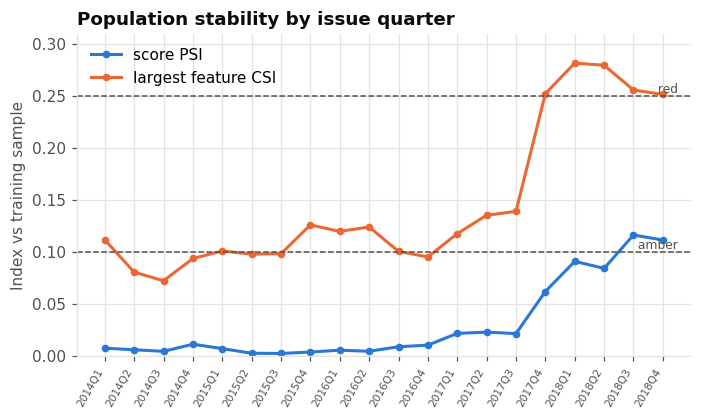

,loans,score_psi,max_csi,max_csi_feature
quarter,,,,
2014Q1,34074,0.0073,0.1115,purpose
2014Q2,37881,0.0057,0.0804,purpose
2014Q3,40595,0.0042,0.0721,purpose
2014Q4,50020,0.0111,0.0936,fico
2015Q1,56568,0.0068,0.1008,purpose
2015Q2,64222,0.0024,0.0977,purpose
2015Q3,73567,0.0022,0.0982,purpose
2015Q4,88669,0.0036,0.1259,purpose
2016Q1,96120,0.0053,0.1196,dti


In [4]:
stab = MON.stability_by_quarter(cm, S["train"], stream)
plots.monitoring_stability(stab); plt.show()
stab[["loans", "score_psi", "max_csi", "max_csi_feature"]]

## 3. Input data quality: the model's own inputs

In [5]:
quality = MON.data_quality_by_quarter(S["train"], stream, list(cm.card.features))
quality[["max_missing_change", "max_missing_feature", "max_out_of_range", "max_out_of_range_feature"]]

,max_missing_change,max_missing_feature,max_out_of_range,max_out_of_range_feature
quarter,,,,
2014Q1,0.0000,fico,0.0001,revol_util
2014Q2,0.0000,fico,0.0001,revol_util
2014Q3,0.0000,fico,0.0146,dti
2014Q4,0.0000,fico,0.0332,dti
2015Q1,0.0000,fico,0.0353,dti
2015Q2,0.0000,fico,0.0346,dti
2015Q3,0.0000,fico,0.0332,dti
2015Q4,0.0000,dti,0.0348,dti
2016Q1,0.0001,dti,0.0513,dti


## 4. Prediction drift

In [6]:
preds = MON.predictions_by_quarter(cm, stream, float(cm.predict_pd(S["oot"]).mean()))
preds

,loans,mean_pd,mean_pd_shift,grade_1,grade_2,grade_3,grade_4,grade_5,grade_6,grade_7
quarter,,,,,,,,,,
2014Q1,34074,0.1370,0.0392,0.1165,0.1385,0.1408,0.1482,0.1502,0.1521,0.1537
2014Q2,37881,0.1371,0.0399,0.1249,0.1333,0.1443,0.1416,0.1478,0.1497,0.1585
2014Q3,40595,0.1366,0.0363,0.1262,0.1354,0.1412,0.1443,0.1485,0.1492,0.1551
2014Q4,50020,0.1382,0.0482,0.1135,0.1322,0.1438,0.1436,0.1530,0.1561,0.1578
2015Q1,56568,0.1366,0.0363,0.1183,0.1366,0.1450,0.1457,0.1508,0.1497,0.1538
2015Q2,64222,0.1340,0.0169,0.1274,0.1421,0.1463,0.1479,0.1464,0.1460,0.1439
2015Q3,73567,0.1298,-0.0150,0.1443,0.1497,0.1510,0.1428,0.1422,0.1401,0.1298
2015Q4,88669,0.1288,-0.0229,0.1492,0.1509,0.1503,0.1450,0.1420,0.1353,0.1274
2016Q1,96120,0.1279,-0.0299,0.1532,0.1524,0.1503,0.1453,0.1416,0.1333,0.1239


## 5. Early performance

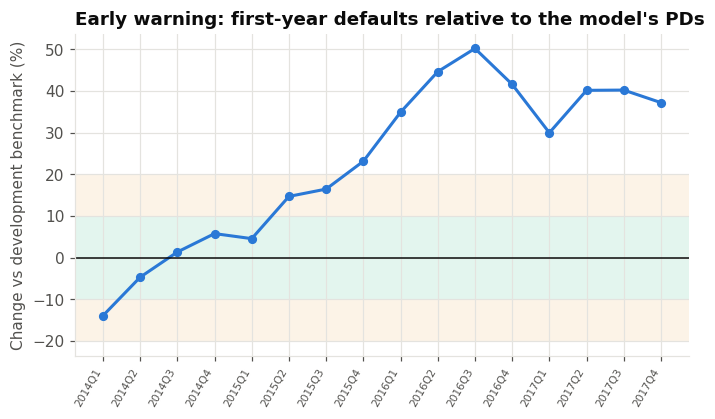

,loans,early_dr,mean_pd,ratio,gini_early,ratio_shift
quarter,,,,,,
2014Q1,34074.0000,0.0408,0.1370,0.2976,0.2925,-0.1391
2014Q2,37881.0000,0.0452,0.1371,0.3295,0.3045,-0.0468
2014Q3,40595.0000,0.0479,0.1366,0.3504,0.3053,0.0136
2014Q4,50020.0000,0.0505,0.1382,0.3657,0.3128,0.0578
2015Q1,56568.0000,0.0494,0.1366,0.3615,0.2983,0.0457
2015Q2,64222.0000,0.0531,0.1340,0.3965,0.3024,0.1470
2015Q3,73567.0000,0.0523,0.1298,0.4026,0.3197,0.1646
2015Q4,88669.0000,0.0548,0.1288,0.4257,0.2993,0.2313
2016Q1,96120.0000,0.0596,0.1279,0.4663,0.2983,0.3489


In [7]:
early = MON.early_performance_by_quarter(cm, stream, bench)
plots.monitoring_early_warning(early, C.MON_EARLY_RATIO_SHIFT); plt.show()
early

In [8]:
recent = production[production["months_observed"] >= C.EARLY_MIN_MONTHS_OBSERVED]
MON.segment_early(cm, recent, SE.default_segments(recent), bench)

,loans,early_dr,mean_pd,ratio,ratio_shift,gini_early
segment,,,,,,
All loans,643914.0000,0.0604,0.1249,0.4832,0.3977,0.2783
FICO below 680,218607.0000,0.0794,0.1642,0.4836,0.3989,0.1891
FICO 740 and above,78641.0000,0.0290,0.0563,0.5141,0.4871,0.3419
Debt-to-income above 25,150404.0000,0.0809,0.1519,0.5326,0.5406,0.2229
Income below $40k,112892.0000,0.0753,0.1780,0.4230,0.2235,0.1993
Income $100k and above,135641.0000,0.0482,0.0836,0.5771,0.6693,0.3296
Renters,269017.0000,0.0708,0.1441,0.4914,0.4216,0.2433
Mortgage holders,293643.0000,0.0498,0.1059,0.4698,0.3591,0.2987
Debt consolidation,346796.0000,0.0635,0.1334,0.4761,0.3771,0.2703


## 6. Performance on matured vintages

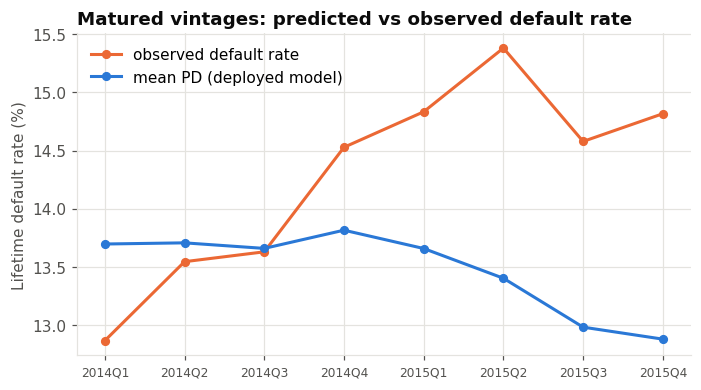

,loans,observed_dr,mean_pd,cal_gap,eo_ratio,gini,ks,gini_drop,cal_intercept,cal_slope,grades_failing
quarter,,,,,,,,,,,
2014Q1,34074.0000,0.1287,0.1370,0.0083,1.0646,0.2804,0.2107,0.0529,-0.0748,0.8991,0.0000
2014Q2,37881.0000,0.1355,0.1371,0.0016,1.0120,0.2976,0.2203,-0.0053,-0.0143,0.9579,0.0000
2014Q3,40595.0000,0.1363,0.1366,0.0003,1.0022,0.3029,0.2202,-0.0230,-0.0026,0.9653,0.0000
2014Q4,50020.0000,0.1453,0.1382,-0.0071,0.9510,0.2894,0.2093,0.0225,0.0608,0.9507,4.0000
2015Q1,56568.0000,0.1483,0.1366,-0.0118,0.9208,0.2897,0.2114,0.0216,0.0999,0.9419,5.0000
2015Q2,64222.0000,0.1538,0.1340,-0.0198,0.8714,0.2902,0.2104,0.0196,0.1671,0.9388,6.0000
2015Q3,73567.0000,0.1458,0.1298,-0.0160,0.8905,0.3043,0.2185,-0.0278,0.1396,0.9830,6.0000
2015Q4,88669.0000,0.1482,0.1288,-0.0194,0.8692,0.2978,0.2144,-0.0059,0.1690,0.9553,7.0000


In [9]:
validated_gini = V.discrimination(S["oot"]["default"], cm.predict_pd(S["oot"]))["gini"]
perf = MON.performance_by_quarter(cm, matured, validated_gini)
plots.monitoring_calibration(perf); plt.show()
perf

## 7. Alerts and triggers

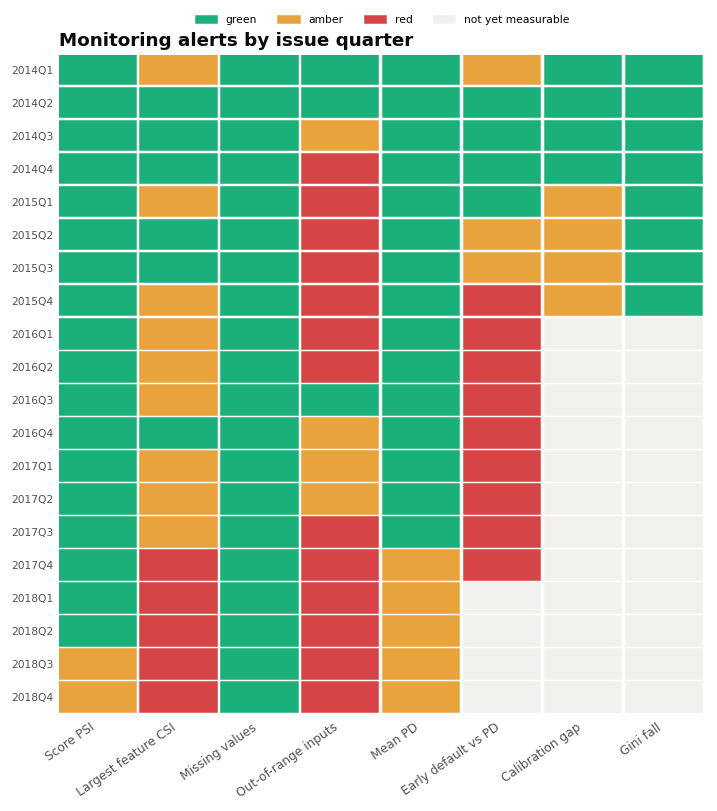

fired
action      rule                                                     
Recalibrate Calibration gap AMBER or RED in the latest matu...   True
            Any grade failing the binomial test at 1% in th...   True
            Early default vs PD AMBER or RED for two quarte...   True
Redevelop   Score PSI or largest feature CSI RED in any qua...   True
            Gini fall RED in any matured quarter                False
            Early default vs PD RED for four quarters in a ...   True

In [10]:
tables = {"stability": stab, "quality": quality, "predictions": preds, "early": early, "performance": perf}
grid = MON.alert_grid(tables)
plots.alert_heatmap(grid); plt.show()
MON.triggers(grid, perf)

In [11]:
MON.alert_log(tables, grid)

,,status,value,amber_at,red_at,watches
quarter,metric,,,,,
2018Q3,Score PSI,AMBER,0.1161,0.1000,0.2500,shift in the score distribution
2018Q4,Score PSI,AMBER,0.1113,0.1000,0.2500,shift in the score distribution
2014Q1,Largest feature CSI,AMBER,0.1115,0.1000,0.2500,shift in any one input
2015Q1,Largest feature CSI,AMBER,0.1008,0.1000,0.2500,shift in any one input
2015Q4,Largest feature CSI,AMBER,0.1259,0.1000,0.2500,shift in any one input
2016Q1,Largest feature CSI,AMBER,0.1196,0.1000,0.2500,shift in any one input
2016Q2,Largest feature CSI,AMBER,0.1239,0.1000,0.2500,shift in any one input
2016Q3,Largest feature CSI,AMBER,0.1003,0.1000,0.2500,shift in any one input
2017Q1,Largest feature CSI,AMBER,0.1174,0.1000,0.2500,shift in any one input


## Findings
- The score distribution stays stable (PSI below 0.10 until 2018Q3), so a check on the score alone would
  have missed the problem.
- First-year defaults outran the PDs: against the development benchmark (34.6% of the mean PD), the
  ratio was RED from 2015Q4 onward, +35% to +50% across 2016 and +30% to +40% across 2017.
- Borrowers looked safer on paper while defaulting more: the mean PD fell 15% by 2018 and the share of
  grade 1 loans rose from 15% to 20–22%.
- Debt-to-income exceeded the training maximum for up to 6.6% of loans in a quarter, and revolving
  utilisation shifted enough to turn RED from 2017Q4.
- On matured 2015 loans the deployed model under-predicts every quarter by 1.2–2.0 points, while Gini
  stays within 6% of its validated level.
- Recalibration is triggered by late 2016 and redevelopment by late 2017, both from signals available
  long before the loans matured.